# Decision Tree- Claimants prediction

### 1. Business Undestanding

In [1]:
#output
# Claimants hire an attornoy or not 
# understand which type of customers are more likely to do 


### 2. Data Collection

#### 2.1. Import nesessary library and dataset

In [2]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
import pickle

claimants_data =pd.read_csv(r'C:\Users\Senthil\Desktop\Data Science\jupyter\ML\2.Logistic Regression\claimants.csv')

### 3. Data Understanding

#### 3.1 perform Initial investigation on the data

In [3]:
# shape 
claimants_data.shape
print(claimants_data.shape)


# Null check
claimants_data.isna().sum()
print(claimants_data.isna().sum())

# data types
claimants_data.dtypes
print(claimants_data.dtypes)

(1340, 7)
CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64
CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object


### 4. Data preparation

#### 4.1 Data Cleaning

In [4]:
claimants_data.dropna(inplace = True)

In [5]:
# duplicates check 
claimants_data.duplicated().unique()
print(claimants_data.duplicated().unique()) 

# describe
claimants_data.describe()

[False]


,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000
mean,11244.278285,0.472628,0.564781,0.904197,0.018248,28.587591,3.856578
std,9425.386224,0.499478,0.496012,0.294455,0.133909,20.392621,10.473239
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4502.750000,0.000000,0.000000,1.000000,0.000000,9.000000,0.440000
50%,8730.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.311000
75%,16013.000000,1.000000,1.000000,1.000000,0.000000,43.000000,3.910500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


#### 4.2 Input and output features

In [6]:
x = claimants_data.iloc[:,2:] #input features 
x

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [7]:
claimants_data.iloc[:,1]

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

In [8]:
y = claimants_data['ATTORNEY']
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

### 5. Model Building

#### 5.1 Model Validation Techniques 

##### Train Test Split

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.20,
                                                    shuffle=True,random_state=39)

##### K fold cross validation

In [17]:
from sklearn.model_selection import KFold,cross_val_score

kfold = KFold(n_splits=5,shuffle=True,random_state= 39)

cv_score = cross_val_score(estimator= rf_model,X=x,y=y,cv = kfold)
print(cv_score.mean().round(2))
print(cv_score.std().round(2))

0.73
0.03


##### LOOCV

In [19]:
from sklearn.model_selection import LeaveOneOut

loocv = LeaveOneOut()

cv_score = cross_val_score(estimator= rf_model,X=x,y=y,cv = loocv)
print(cv_score.mean().round(2))
print(cv_score.std().round(2))

0.73
0.44


In [12]:
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,VotingClassifier

In [13]:
rf_model = RandomForestClassifier(max_depth = 5)

### 6. Model training

In [45]:
rf_model.fit(x,y)

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


#### Grid search CV(Cross validation)

In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
gridsearch = GridSearchCV(estimator = rf_model,param_grid= {"max_depth":[5,6,7,8,9,10],
                                                           "criterion":['gini','entropy'],
                                                           "n_estimators":[25,50,75,100]})
gridsearch.fit(x,y)

print(gridsearch.best_params_)
print(gridsearch.best_score_)

{'criterion': 'entropy', 'max_depth': 6, 'n_estimators': 75}
0.7326442507264426


In [49]:
rf_model1 = RandomForestClassifier(criterion='entropy',max_depth=6,n_estimators= 75)
rf_model1.fit(X_train,y_train)

,n_estimators,75
,criterion,'entropy'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 7. Model testing

##### Training data

In [50]:
y_pred_train = rf_model1.predict(X_train)

##### Testing data

In [51]:
y_pred_test = rf_model1.predict(X_test)

### 8. Model Evaluation

In [17]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,roc_curve,roc_auc_score

##### 8.1 Evaluation metrics for Training data

In [53]:
print(confusion_matrix(y_train,y_pred_train))

[[365  92]
 [112 307]]


In [54]:
print(classification_report(y_train,y_pred_train))

              precision    recall  f1-score   support

           0       0.77      0.80      0.78       457
           1       0.77      0.73      0.75       419

    accuracy                           0.77       876
   macro avg       0.77      0.77      0.77       876
weighted avg       0.77      0.77      0.77       876



In [55]:
accuracy_score(y_train,y_pred_train)

0.7671232876712328

##### ROC Curve - Receiver Operating Characteristics
AUC - Area Under this Curve

0.7656919935451189


Text(0, 0.5, 'True Positive Rate')

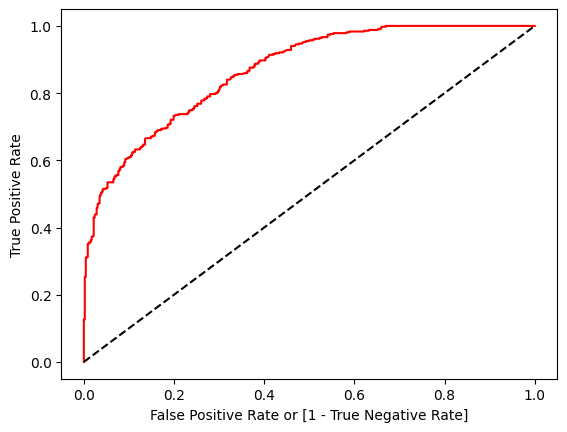

In [56]:
fpr, tpr, thresholds = roc_curve(y_train, rf_model1.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

##### 8.2 Evaluation metrics for  Test data

In [57]:
print(confusion_matrix(y_test,y_pred_test))

[[96 25]
 [29 70]]


In [58]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.77      0.79      0.78       121
           1       0.74      0.71      0.72        99

    accuracy                           0.75       220
   macro avg       0.75      0.75      0.75       220
weighted avg       0.75      0.75      0.75       220



In [59]:
accuracy_score(y_test,y_pred_test)

0.7545454545454545

##### ROC Curve - Receiver Operating Characteristics
AUC - Area Under this Curve

AUC: 0.7502295684113867


Text(0, 0.5, 'True Positive Rate')

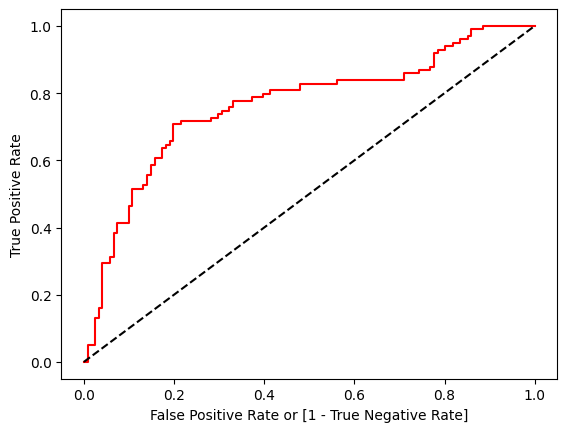

In [60]:
fpr, tpr, thresholds = roc_curve(y_test, rf_model1.predict_proba(X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print("AUC:",auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

### 9. Model Deployment

In [61]:
pickle.dump(obj = rf_model1,file = open(file = 'RF_intelligence_file.pkl',mode = 'wb'))

In [62]:
rf_intel_pkl = pickle.load(file = open(file = 'RF_intelligence_file.pkl',mode = 'rb'))

In [63]:
rf_intel_pkl.predict(X_test)

array([0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0])